# 04 - Multi-Step Policy Gradients, Actor-Critic, and PPO

## Imports

In [1]:
import itertools
import warnings
import numpy as np
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=RuntimeWarning)   # numpy on some Macs warns spuriously inside matmul

# Make sure we get outputs from a probabilistic model each time (for reproducibility)
np.random.seed(1515)

## What `02` Left Out

`02` trained a policy on one decision, isolating the first pick to keep the update easy to follow. That was fair, but it skipped the hard part of this whole subject. A real policy makes a sequence of choices, and the reward for early choices arrives late.

It also named two ideas without building either. **Actor-Critic** got a paragraph, and `genai_architecture_primer/05` says real RLHF uses **PPO**, which no notebook here has explained. This notebook builds all of it on one problem, so you can see what each piece fixes:

1. Policy gradient across several steps, where one action's credit has to come from rewards that show up later.
2. Why that update is noisy, and the two fixes for it (a baseline, then a learned critic).
3. Why you can't simply reuse a batch of experience for many gradient steps, and the clipping trick PPO uses to make that safe.

## A Longer Draft

`01`'s draft was 2 picks from 3 teams, short enough that discounting barely mattered. We'll use 3 picks from 5 teams, the same reward structure (each pick's quality, plus a synergy bonus once the alliance has both a strong climber and a strong auto scorer), and a few more teams to choose between.

To make credit assignment real, the bonus only arrives after the last pick. Whether pick 1 was a good idea depends on whether picks 2 and 3 complete the pair, so the agent doesn't know until the end. The final reward is also made noisy, because a real alliance's score also depends on how the real matches go. The agent never sees the draft's true value directly, so we add Gaussian noise with SD = 8 to the last reward. We use $\gamma = 1$ here (no discounting), like `02` did, so a sequence's value is just its total.

In [2]:
CLIMB_POINTS = {1: 10, 2: 20, 3: 30}
STRONG_CLIMBER = 0.7
STRONG_AUTO = 15.0
SYNERGY_BONUS = 10.0
NUM_PICKS = 3
MATCH_NOISE = 8.0

TEAMS = {
    'A': {'climb': 0.9, 'level': 3, 'auto': 3.0},
    'B': {'climb': 0.4, 'level': 1, 'auto': 18.0},
    'C': {'climb': 0.5, 'level': 2, 'auto': 9.0},
    'D': {'climb': 0.8, 'level': 2, 'auto': 6.0},
    'E': {'climb': 0.3, 'level': 1, 'auto': 16.0},
}
NAMES = sorted(TEAMS)

def climb_points(team):
    return team['climb'] * CLIMB_POINTS[team['level']]

def quality(team):
    return climb_points(team) + team['auto']

def has_climber(picked):
    return any(TEAMS[t]['climb'] > STRONG_CLIMBER for t in picked)

def has_auto(picked):
    return any(TEAMS[t]['auto'] > STRONG_AUTO for t in picked)

def synergy(picked):
    return SYNERGY_BONUS if has_climber(picked) and has_auto(picked) else 0.0

def true_total(picked):
    return sum(quality(TEAMS[t]) for t in picked) + synergy(picked)

ALL_ALLIANCES = sorted(itertools.combinations(NAMES, NUM_PICKS), key=true_total, reverse=True)
BEST_TOTAL = true_total(ALL_ALLIANCES[0])

print(f"Best alliances by true value (before noise):")
for alliance in ALL_ALLIANCES[:4]:
    print(f"  {alliance}  {true_total(alliance):.1f}")

Best alliances by true value (before noise):
  ('A', 'B', 'D')  84.0
  ('A', 'B', 'C')  81.0
  ('A', 'B', 'E')  81.0
  ('A', 'D', 'E')  81.0


Because the problem is this small, we can list every alliance and find the true best one by hand: `('A', 'B', 'D')` at 84, with three alliances tied at 81 behind it. We'll check each learned policy against that, the same way `02` checked against `REWARD_MEANS`. Order doesn't matter to the total (no discounting), but it matters to the agent, since each pick can only be made from whichever teams are left.

## The Policy: Scoring Each Candidate

The draft's action space changes every turn, since a team that's already picked can't be picked again. A fixed 5-way softmax would waste probability on invalid picks. Instead, one small network scores each remaining candidate (given its stats and what's already been picked), and a softmax runs over only the candidates still available. That's the same scoring network as `01`'s value network, with its output read as a logit instead of a Q-value.

In [3]:
def relu(z):
    return np.maximum(0, z)

class Net:
    """ in -> hidden ReLU -> 1 output. Same body as the value network from 01. """
    def __init__(self, n_in, hidden=16):
        self.W1 = np.random.randn(hidden, n_in) * 0.5
        self.b1 = np.zeros((hidden, 1))
        self.W2 = np.random.randn(1, hidden) * 0.5
        self.b2 = np.zeros((1, 1))

    def forward(self, X):
        z1 = self.W1 @ X + self.b1
        a1 = relu(z1)
        return z1, a1, self.W2 @ a1 + self.b2

    def gradients(self, X, d_out):
        z1, a1, _ = self.forward(X)
        d_z1 = (self.W2.T @ d_out) * (z1 > 0)
        return [d_z1 @ X.T, d_z1.sum(axis=1, keepdims=True), d_out @ a1.T, d_out.sum(axis=1, keepdims=True)]

    def apply(self, grads, learning_rate):
        for param, g in zip([self.W1, self.b1, self.W2, self.b2], grads):
            param -= learning_rate * g

def candidate_features(name, picked):
    team = TEAMS[name]
    return np.array([
        team['climb'] - 0.5,
        (climb_points(team) - 10) / 10,
        (team['auto'] - 10) / 8,
        (1.0 if has_climber(picked) else 0.0) - 0.5,
        (1.0 if has_auto(picked) else 0.0) - 0.5,
        (NUM_PICKS - len(picked)) - 2.0,
    ])

def state_features(picked):
    return np.array([1.0 if n in picked else 0.0 for n in NAMES] + [(NUM_PICKS - len(picked)) - 1.0])

In [4]:
def action_probs(actor, picked):
    remaining = [n for n in NAMES if n not in picked]
    X = np.stack([candidate_features(n, picked) for n in remaining], axis=1)
    logits = actor.forward(X)[2].ravel()
    p = np.exp(logits - logits.max())
    return remaining, X, p / p.sum()

def sample_episode(actor):
    picked, steps = tuple(), []
    for _ in range(NUM_PICKS):
        remaining, X, p = action_probs(actor, picked)
        k = np.random.choice(len(remaining), p=p)
        steps.append({'X': X, 'k': k, 'old_p': p[k], 'state': state_features(picked),
                      'r': quality(TEAMS[remaining[k]])})
        picked = picked + (remaining[k],)
    steps[-1]['r'] += synergy(picked) + np.random.normal(0, MATCH_NOISE)
    g = 0.0
    for step in reversed(steps):
        g += step['r']
        step['G'] = g
    return steps, picked

def exact_expected_return(actor):
    total = 0.0
    for seq in itertools.permutations(NAMES, NUM_PICKS):
        prob, picked = 1.0, tuple()
        for name in seq:
            remaining, _, p = action_probs(actor, picked)
            prob *= p[remaining.index(name)]
            picked = picked + (name,)
        total += prob * true_total(seq)
    return total

`sample_episode` plays one full draft with the current policy, and records for each step the candidate features, the pick it made, and its probability at that moment (`old_p`, which PPO will need later). It also stores each step's **return-to-go**, `G`, which is where the multi-step part lives.

## Credit Assignment: Return-to-Go

In `02`, a pick's reward was the whole story. Now each action should be judged by what came after it. Pick 1's consequences include picks 2 and 3, but pick 3 can't be responsible for a reward that arrived before it. The return-to-go $G_t$ is the sum of rewards from step $t$ to the end:

$$ G_t = r_t + r_{t+1} + \dots + r_T $$

and the policy gradient update from `02` just swaps the single-step reward for it:

$$ \text{Loss}_t = -(G_t - b) \cdot \log \pi(a_t \mid s_t) $$

This is also what `01`'s Q-learning did with $\gamma \max_{a'} Q(s',a')$, except Q-learning estimates the future with a learned value, and this version uses the future that actually happened. That makes the estimate honest but noisy, since a whole episode of luck lands in one number.

First, plain REINFORCE, with $b = 0$: every action gets credit equal to its raw return-to-go.

In [5]:
def train(method, iterations=150, batch=4, learning_rate=0.01, epochs=1, clip=0.2, seed=0):
    """ method: 'reinforce' | 'baseline' | 'actor_critic' | 'unclipped' | 'ppo'
    Returns (exact expected true return per iteration, root-mean-square advantage per iteration, final actor). """
    np.random.seed(seed)
    actor, critic = Net(6), Net(6)
    running_baseline = None
    returns, advantage_rms = [], []

    for _ in range(iterations):
        steps = [s for _ in range(batch) for s in sample_episode(actor)[0]]
        G = np.array([s['G'] for s in steps])
        S = np.stack([s['state'] for s in steps], axis=1)

        if method == 'reinforce':
            advantage = G
        elif method == 'baseline':
            running_baseline = G.mean() if running_baseline is None else 0.9 * running_baseline + 0.1 * G.mean()
            advantage = G - running_baseline
        else:
            advantage = G - critic.forward(S)[2].ravel()
        advantage_rms.append(np.sqrt((advantage ** 2).mean()))

        for _ in range(epochs):
            grads = [np.zeros_like(p) for p in [actor.W1, actor.b1, actor.W2, actor.b2]]
            for s, adv in zip(steps, advantage):
                logits = actor.forward(s['X'])[2].ravel()
                p = np.exp(logits - logits.max())
                p /= p.sum()
                onehot = np.zeros_like(p)
                onehot[s['k']] = 1.0
                weight = adv
                if method in ('unclipped', 'ppo'):
                    ratio = p[s['k']] / s['old_p']
                    weight = adv * ratio
                    if method == 'ppo' and ((adv > 0 and ratio > 1 + clip) or (adv < 0 and ratio < 1 - clip)):
                        weight = 0.0
                for g, new in zip(grads, actor.gradients(s['X'], (weight * (p - onehot)).reshape(1, -1))):
                    g += new
            actor.apply([g / len(steps) for g in grads], learning_rate)

        if method in ('actor_critic', 'unclipped', 'ppo'):
            for _ in range(20):
                v = critic.forward(S)[2]
                critic.apply(critic.gradients(S, 2 * (v - G.reshape(1, -1)) / S.shape[1]), 0.01)

        returns.append(exact_expected_return(actor))
    return np.array(returns), np.array(advantage_rms), actor

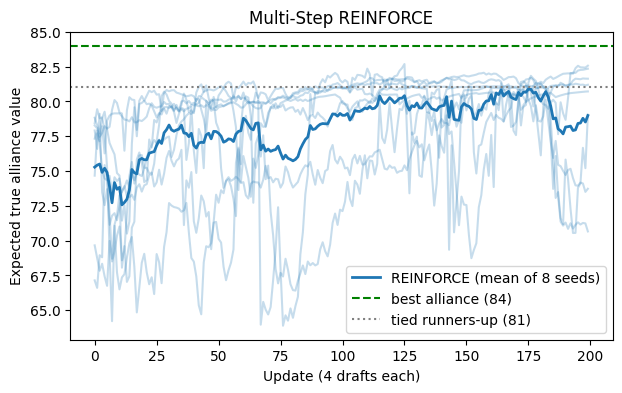

Untrained policy (mean of 20 random inits): 73.2
REINFORCE, mean of last 20:      78.8
  worst seed vs. best seed:      73.9 vs. 81.9


In [6]:
n_seeds = 8
reinforce_runs = [train('reinforce', iterations=200, batch=4, seed=s) for s in range(n_seeds)]
reinforce_returns = np.array([r[0] for r in reinforce_runs])

plt.figure(figsize=(7, 4))
for r in reinforce_returns:
    plt.plot(r, color="tab:blue", alpha=0.25)
plt.plot(reinforce_returns.mean(axis=0), color="tab:blue", linewidth=2, label="REINFORCE (mean of 8 seeds)")
plt.axhline(BEST_TOTAL, color="green", linestyle="--", label=f"best alliance ({BEST_TOTAL:.0f})")
plt.axhline(true_total(ALL_ALLIANCES[1]), color="gray", linestyle=":", label="tied runners-up (81)")
plt.xlabel("Update (4 drafts each)")
plt.ylabel("Expected true alliance value")
plt.title("Multi-Step REINFORCE")
plt.legend()
plt.show()

print(f"Untrained policy (mean of 20 random inits): {np.mean([exact_expected_return(Net(6)) for _ in range(20)]):.1f}")
print(f"REINFORCE, mean of last 20:      {reinforce_returns[:, -20:].mean():.1f}")
print(f"  worst seed vs. best seed:      {reinforce_returns[:, -20:].mean(axis=1).min():.1f} vs. {reinforce_returns[:, -20:].mean(axis=1).max():.1f}")

It learns. The mean climbs from about 73 to about 79, and the best seed gets above 81. But look at the spread. The same algorithm on different random seeds finishes anywhere from about 74 to about 82, and individual curves lurch up and down along the way. Nothing in the update is wrong. It's noisy, because each action is judged by a return that carries a whole episode's luck. Nothing reaches 84 yet either.

## Why It's Noisy, and the Baseline

REINFORCE is weighting each action by the raw return-to-go. Pick 1's return is the whole draft, around 75. Pick 3's is just its own reward, closer to 20. Every one of those numbers is positive and large, so every action that was taken gets pushed up, and what separates a good pick from a bad one is a small difference sitting on top of a big shared offset. The noise we added to the final reward rides in on every step.

`02` already had the fix. We subtract a baseline, so an action is weighted by how much better than usual it did, not by its raw size. Subtracting a baseline that doesn't depend on the action leaves the expected gradient the same and removes the shared offset. The running-average baseline from `02` works, but it's blunt. It uses the same number for pick 1 (where about 75 is normal) as for pick 3 (where about 20 is normal), so it still leaves a big step-to-step offset in the weights.

A better baseline knows what step you're on, and what's already been picked.

## Actor-Critic

That baseline is a value function. $V(s)$ is the expected return from a state, which is exactly what `01`'s value network estimated, and now it earns its keep. An **Actor-Critic** trains two networks side by side.

The **actor** is the policy network above, and picks actions. The **critic** is a value network over the state (here: which teams are already picked, and how many picks remain), regressed toward the returns that actually happened.

The weight on each action becomes the **Advantage**, or how much better the return was than the critic expected from that state:

$$ A_t = G_t - V(s_t) $$

Everything in `train` already supports this. The critic is trained with a few regression steps on each batch of returns, and `advantage = G - critic(state)`. We'll compare three versions of the same update on the same drafts, differing only in what gets subtracted from $G_t$: nothing, a running average, or the critic.

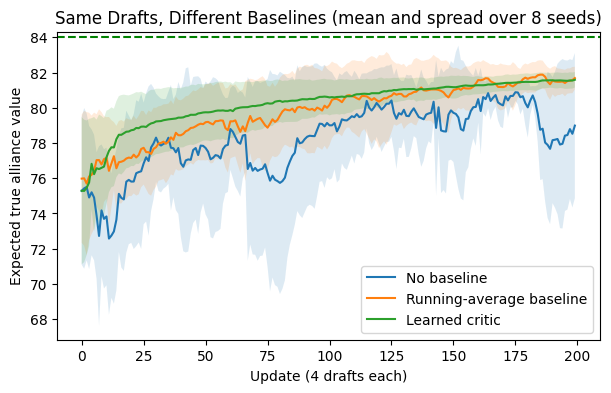

                             final value    seed-to-seed std   RMS advantage
No baseline                         78.8                3.05            58.1
Running-average baseline            81.6                0.73            22.1
Learned critic                      81.5                0.45            10.5


In [7]:
compare = {}
for method in ['reinforce', 'baseline', 'actor_critic']:
    runs = [train(method, iterations=200, batch=4, seed=s) for s in range(n_seeds)]
    compare[method] = {"returns": np.array([r[0] for r in runs]), "rms": np.array([r[1] for r in runs])}

labels = {'reinforce': 'No baseline', 'baseline': 'Running-average baseline', 'actor_critic': 'Learned critic'}
plt.figure(figsize=(7, 4))
for method, data in compare.items():
    mean, spread = data["returns"].mean(axis=0), data["returns"].std(axis=0)
    plt.plot(mean, label=labels[method])
    plt.fill_between(range(len(mean)), mean - spread, mean + spread, alpha=0.15)
plt.axhline(BEST_TOTAL, color="green", linestyle="--")
plt.xlabel("Update (4 drafts each)")
plt.ylabel("Expected true alliance value")
plt.title("Same Drafts, Different Baselines (mean and spread over 8 seeds)")
plt.legend(loc="lower right")
plt.show()

print(f"{'':26s}{'final value':>14s}{'seed-to-seed std':>20s}{'RMS advantage':>16s}")
for method, data in compare.items():
    final = data["returns"][:, -20:].mean(axis=1)
    print(f"{labels[method]:26s}{final.mean():14.1f}{final.std():20.2f}{data['rms'].mean():16.1f}")

Read the last column of the table first, since it's the typical size of the number each action gets weighted by. With no baseline it's about 58. The running average cuts it to about 22, and the critic cuts it to about 10. That is close to the 8 of match noise we added ourselves, which is about as low as it can go, since nothing can predict that noise.

The curves follow it. With no baseline, learning is jumpy and the worst seeds stall. Both baselines end at about the same value (81.5), but the critic's seeds agree with each other most closely, and it climbs faster early on. At the end, on a problem this small, the critic isn't much better than the running average. What it fixes is the step-to-step offset, and that matters more as episodes get longer and the states differ more from each other.

## Reusing Experience: Why PPO Exists

Everything so far uses each batch of drafts once, takes one gradient step, and throws the batch away. That's what **on-policy** meant in `02`. The update is only valid for the policy that produced the data, and the policy just changed. It is also expensive. Drafts are cheap here, but a real robot or a real language model sample is not, and one gradient step per batch wastes most of what was collected.

The obvious fix is to take many gradient steps on the same batch. Here is what happens if you do exactly that, with no other changes. We'll call it `unclipped`: 20 gradient steps per batch, each weighting the update by the ratio $r = \pi_{\text{new}}(a \mid s) / \pi_{\text{old}}(a \mid s)$, which is the correct importance weight for data collected under an older policy.

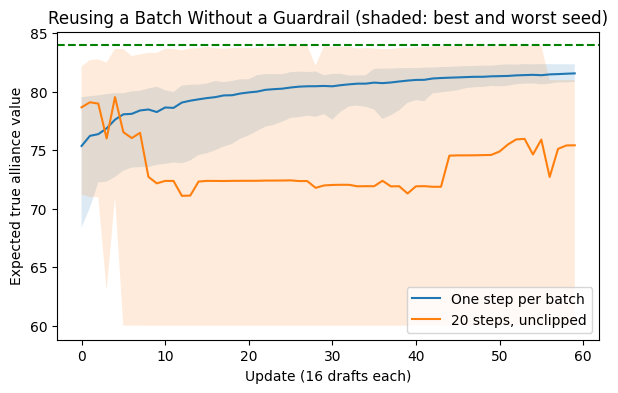

In [8]:
n_updates = 60
ppo_compare = {}
for name, method, epochs in [("One step per batch", "actor_critic", 1), ("20 steps, unclipped", "unclipped", 20)]:
    runs = [train(method, iterations=n_updates, batch=16, learning_rate=0.03, epochs=epochs, seed=s) for s in range(n_seeds)]
    ppo_compare[name] = np.array([r[0] for r in runs])

plt.figure(figsize=(7, 4))
for name, returns in ppo_compare.items():
    mean, lo, hi = returns.mean(axis=0), returns.min(axis=0), returns.max(axis=0)
    plt.plot(mean, label=name)
    plt.fill_between(range(len(mean)), lo, hi, alpha=0.15)
plt.axhline(BEST_TOTAL, color="green", linestyle="--")
plt.xlabel("Update (16 drafts each)")
plt.ylabel("Expected true alliance value")
plt.title("Reusing a Batch Without a Guardrail (shaded: best and worst seed)")
plt.legend(loc="lower right")
plt.show()

Taking 20 steps per batch makes the policy worse, not better. It ends at about 75, and the worst seed finishes at 60, well below where an untrained policy starts. The first few steps on a batch are fine, since the ratio is near 1 and the batch still looks like it came from the current policy. But every step moves the policy further from the one that collected the batch, and the update keeps chasing whatever that batch happened to reward, noise included. Once it has overfit one batch's lucky drafts, the next batch comes from that worse policy. The "one step per batch" line is the safe version from the previous section. It is slow, but it never breaks.

## PPO: A Trust Region Made of One `min`

The fix is a one-line guardrail. **Proximal Policy Optimization (PPO)** keeps the importance ratio $r$, and stops rewarding the policy for moving further once $r$ has already gone past a small window around 1:

$$ L = -\min\Big( r \cdot A,\ \text{clip}(r,\ 1-\epsilon,\ 1+\epsilon) \cdot A \Big) $$

Read it by cases. If an action had a positive advantage, the update raises its probability, but only until $r$ reaches $1 + \epsilon$, and past that the loss stops improving, so the gradient is zero. If an action had a negative advantage, the update lowers its probability only until $r$ reaches $1 - \epsilon$. Inside the window the update is the ordinary policy gradient. Outside it, for the direction the advantage wanted, it does nothing. The policy can take as many steps as it likes on one batch, but it can't move far from the policy that collected the data, which is the condition that keeps the batch's estimate trustworthy.

In `train`, the difference from `unclipped` is one short `if` (under `method == 'ppo'`): the update's weight is set to 0 whenever the ratio is outside the window in the direction the advantage was pushing it. Use $\epsilon = 0.2$, the usual default.

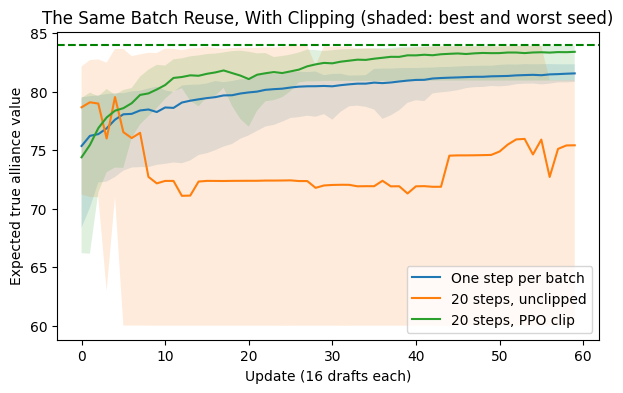

                          value at update 10   final value   worst seed
One step per batch                      78.5          81.5         80.7
20 steps, unclipped                     72.4          75.2         60.0
20 steps, PPO clip                      80.5          83.4         81.0


In [9]:
runs = [train('ppo', iterations=n_updates, batch=16, learning_rate=0.03, epochs=20, clip=0.2, seed=s) for s in range(n_seeds)]
ppo_compare["20 steps, PPO clip"] = np.array([r[0] for r in runs])
ppo_actors = [r[2] for r in runs]

plt.figure(figsize=(7, 4))
for name, returns in ppo_compare.items():
    mean, lo, hi = returns.mean(axis=0), returns.min(axis=0), returns.max(axis=0)
    plt.plot(mean, label=name)
    plt.fill_between(range(len(mean)), lo, hi, alpha=0.15)
plt.axhline(BEST_TOTAL, color="green", linestyle="--")
plt.xlabel("Update (16 drafts each)")
plt.ylabel("Expected true alliance value")
plt.title("The Same Batch Reuse, With Clipping (shaded: best and worst seed)")
plt.legend(loc="lower right")
plt.show()

print(f"{'':24s}{'value at update 10':>20s}{'final value':>14s}{'worst seed':>13s}")
for name, returns in ppo_compare.items():
    print(f"{name:24s}{returns[:, 8:12].mean():20.1f}{returns[:, -10:].mean():14.1f}{returns[:, -10:].mean(axis=1).min():13.1f}")

Same 20 steps per batch, with the clip. The final value is 83.4, against 75.2 unclipped and 81.5 for one step per batch. It's also faster, since by update 10 it's at 80.5 where one step per batch is at 78.5, because it gets 20 steps of learning out of every batch of drafts. And its worst seed finishes at 81.0, where the unclipped worst seed finished at 60.0. The clip didn't slow learning down. It made large steps safe.

## What Real PPO Adds

What we built is the core of PPO. Production implementations add several things on top, none of which change the idea.

**Generalized Advantage Estimation (GAE)** blends the return-to-go with the critic's own predictions (the bootstrapping from `01`'s TD learning) to trade noise for bias on long episodes. Our episodes are three steps long, so we skipped it.

**Minibatches and an entropy bonus** ensure each update sees shuffled slices of the batch, and so the policy keeps some exploration (the same worry as `02`'s calibration section). `06-imitation-then-rl.ipynb` shows why it matters: a policy cloned from demonstrations is too sure of itself for PPO to change at all without one.

**Value-function clipping and a KL penalty or early stopping** are extra guardrails on the critic and on how far the policy has drifted. `06` also shows the KL penalty doing real work, keeping fine-tuning from undoing a cloned starting policy.

This is the algorithm `genai_architecture_primer/05` names for RLHF, with the language model as the actor and a learned reward model standing in for our noisy match score. The "weight each token by its advantage" description from that notebook is this update, applied once per generated token. DPO, which the same notebook mentions, skips this whole loop by training directly on preference pairs.

## Does the Learned Policy Match What We Worked Out?

The standard check from `01` and `02` was to compare against the answer we found by hand. Because there are only 10 possible alliances, we can compute each one's probability under the trained policy exactly, by multiplying out the step-by-step pick probabilities for every ordering that produces it.

In [10]:
def alliance_probabilities(actor):
    probs = {alliance: 0.0 for alliance in ALL_ALLIANCES}
    for seq in itertools.permutations(NAMES, NUM_PICKS):
        prob, picked = 1.0, tuple()
        for name in seq:
            remaining, _, p = action_probs(actor, picked)
            prob *= p[remaining.index(name)]
            picked = picked + (name,)
        probs[tuple(sorted(seq))] += prob
    return probs

mean_probs = {a: np.mean([alliance_probabilities(actor)[a] for actor in ppo_actors]) for a in ALL_ALLIANCES}
print(f"{'alliance':16s}{'true value':>12s}{'policy probability (mean of 8 PPO seeds)':>44s}")
for alliance in ALL_ALLIANCES:
    print(f"{str(alliance):16s}{true_total(alliance):12.1f}{mean_probs[alliance]:44.2f}")

alliance          true value    policy probability (mean of 8 PPO seeds)
('A', 'B', 'D')         84.0                                        0.82
('A', 'B', 'C')         81.0                                        0.01
('A', 'B', 'E')         81.0                                        0.13
('A', 'D', 'E')         81.0                                        0.04
('A', 'C', 'E')         78.0                                        0.00
('B', 'C', 'D')         73.0                                        0.00
('B', 'D', 'E')         73.0                                        0.00
('A', 'C', 'D')         71.0                                        0.00
('C', 'D', 'E')         70.0                                        0.00
('B', 'C', 'E')         60.0                                        0.00


The trained policy puts about 82% of its probability on `('A', 'B', 'D')`, the best alliance we found by hand, another 18% on the three alliances tied at 81, and essentially nothing on anything worse. That matches the hand-worked answer.

It isn't 100%, and it shouldn't be. With noise of 8 on every match score, a 3-point gap between 84 and 81 is hard to see from sampled drafts, so a policy that keeps a little probability on the near-ties is being honest about that. This is `02`'s calibration point again.

## Try It Yourself

1. Turn the match noise off (`MATCH_NOISE = 0.0`, then re-run from the top) and then try `20.0`. For which of the three baselines does the gap between methods grow as the noise does, and why?
2. Add a 6th team to `TEAMS` that makes a different alliance the best one (give it a high `climb` and a `level` of 3, say). Does PPO find it? Check the answer against `ALL_ALLIANCES` the way the last section does.
3. Change `clip` from `0.2` to `0.05` and then to `0.5` in the PPO run. Describe how the learning curve changes at each end, and relate it to what the clip window is protecting.

In [11]:
# TODO: 1. change MATCH_NOISE and re-run the baseline comparison

# TODO: 2. add a 6th team, then re-run PPO and compare against ALL_ALLIANCES

# TODO: 3. re-run the PPO training with clip=0.05 and clip=0.5, and plot the curves

## Resources

- [OpenAI Spinning Up: Proximal Policy Optimization](https://spinningup.openai.com/en/latest/algorithms/ppo.html) - a code-adjacent walkthrough of the clipped objective used above, and of the extra details real implementations add (instructional).
- Schulman, Wolski, Dhariwal, Radford & Klimov (2017). ["Proximal Policy Optimization Algorithms."](https://arxiv.org/abs/1707.06347) The PPO paper (paper).
- Schulman, Moritz, Levine, Jordan & Abbeel (2016). ["High-Dimensional Continuous Control Using Generalized Advantage Estimation."](https://arxiv.org/abs/1506.02438) The GAE paper (paper).
- [Sutton & Barto: *Reinforcement Learning: An Introduction*](http://incompleteideas.net/book/the-book.html), Chapter 13 covers policy gradient methods including baselines and actor-critic (textbook).
- [Andrej Karpathy: Deep Reinforcement Learning: Pong from Pixels](https://karpathy.github.io/2016/05/31/rl/) - a readable from-scratch policy gradient walkthrough (blog).